# Task 3: Car Price Prediction with Machine Learning

## Introduction

The used-car market is growing rapidly, and determining the right selling price of a car can be challenging. The price of a used car depends on several factors, such as its brand, age, kilometers driven, fuel type, transmission, engine capacity, and overall condition.

The objective of this project is to develop a Machine Learning model that predicts the selling price of used cars based on different features. The project uses Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn to perform data cleaning, exploratory data analysis, feature engineering, model training, and evaluation.

Two regression algorithms, Linear Regression and Random Forest Regression, are implemented and compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

The best-performing model is then used to predict the selling price of a sample used car.

In [1]:
print("Car Price Prediction Project Started!")

Car Price Prediction Project Started!


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

print(os.listdir())

['car data.csv', 'CAR DETAILS FROM CAR DEKHO.csv', 'Car details v3.csv', 'car details v4.csv', 'car_price_prediction.ipynb']


In [5]:
files = [
    "car data.csv",
    "CAR DETAILS FROM CAR DEKHO.csv",
    "Car details v3.csv",
    "car details v4.csv"
]

for file in files:
    data = pd.read_csv(file)
    print("\nDataset:", file)
    print("Shape:", data.shape)
    print("Columns:", list(data.columns))


Dataset: car data.csv
Shape: (301, 9)
Columns: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

Dataset: CAR DETAILS FROM CAR DEKHO.csv
Shape: (4340, 8)
Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset: Car details v3.csv
Shape: (8128, 13)
Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']

Dataset: car details v4.csv
Shape: (2059, 20)
Columns: ['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']


In [6]:
df = pd.read_csv("Car details v3.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [8]:
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1202


In [10]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("New dataset shape:", df.shape)

Duplicates removed successfully!
New dataset shape: (6926, 13)


In [11]:
print("Fuel Types:")
print(df["fuel"].unique())

print("\nSeller Types:")
print(df["seller_type"].unique())

print("\nTransmission Types:")
print(df["transmission"].unique())

print("\nOwner Types:")
print(df["owner"].unique())

Fuel Types:
<StringArray>
['Diesel', 'Petrol', 'LPG', 'CNG']
Length: 4, dtype: str

Seller Types:
<StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str

Transmission Types:
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

Owner Types:
<StringArray>
[         'First Owner',         'Second Owner',          'Third Owner',
 'Fourth & Above Owner',       'Test Drive Car']
Length: 5, dtype: str


In [12]:
current_year = pd.Timestamp.today().year

df["car_age"] = current_year - df["year"]

print("Car age column created successfully!")
df[["name", "year", "car_age"]].head()

Car age column created successfully!


,name,year,car_age
0,Maruti Swift Dzire VDI,2014,12
1,Skoda Rapid 1.5 TDI Ambition,2014,12
2,Honda City 2017-2020 EXi,2006,20
3,Hyundai i20 Sportz Diesel,2010,16
4,Maruti Swift VXI BSIII,2007,19


In [13]:
df["brand"] = df["name"].str.split().str[0]

print("Car brand column created successfully!")
print(df[["name", "brand"]].head(10))

Car brand column created successfully!
                                   name    brand
0                Maruti Swift Dzire VDI   Maruti
1          Skoda Rapid 1.5 TDI Ambition    Skoda
2              Honda City 2017-2020 EXi    Honda
3             Hyundai i20 Sportz Diesel  Hyundai
4                Maruti Swift VXI BSIII   Maruti
5         Hyundai Xcent 1.2 VTVT E Plus  Hyundai
6          Maruti Wagon R LXI DUO BSIII   Maruti
7                    Maruti 800 DX BSII   Maruti
8                      Toyota Etios VXD   Toyota
9  Ford Figo Diesel Celebration Edition     Ford


In [14]:
df["mileage"] = df["mileage"].str.extract(r"([\d.]+)").astype(float)

df["engine"] = df["engine"].str.extract(r"([\d.]+)").astype(float)

df["max_power"] = df["max_power"].str.extract(r"([\d.]+)").astype(float)

print("Specifications converted into numeric values!")
df[["mileage", "engine", "max_power"]].head()

Specifications converted into numeric values!


,mileage,engine,max_power
0,23.40,1248.0,74.00
1,21.14,1498.0,103.52
2,17.70,1497.0,78.00
3,23.00,1396.0,90.00
4,16.10,1298.0,88.20


In [15]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        206
torque           209
seats            208
car_age            0
brand              0
dtype: int64


In [16]:
numeric_columns = ["mileage", "engine", "max_power", "seats"]

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing numeric values filled successfully!")

print(df[numeric_columns].isnull().sum())

Missing numeric values filled successfully!
mileage      0
engine       0
max_power    0
seats        0
dtype: int64


In [17]:
print("Total missing values:", df.isnull().sum().sum())

print("Final dataset shape:", df.shape)

df.head()

Total missing values: 209
Final dataset shape: (6926, 15)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,car_age,brand
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,12,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,12,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,20,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,16,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,19,Maruti


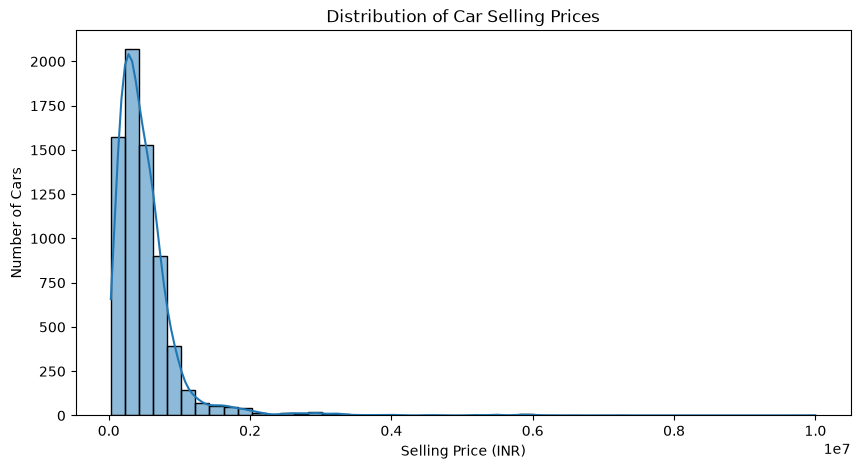

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(df["selling_price"], bins=50, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Number of Cars")

plt.show()

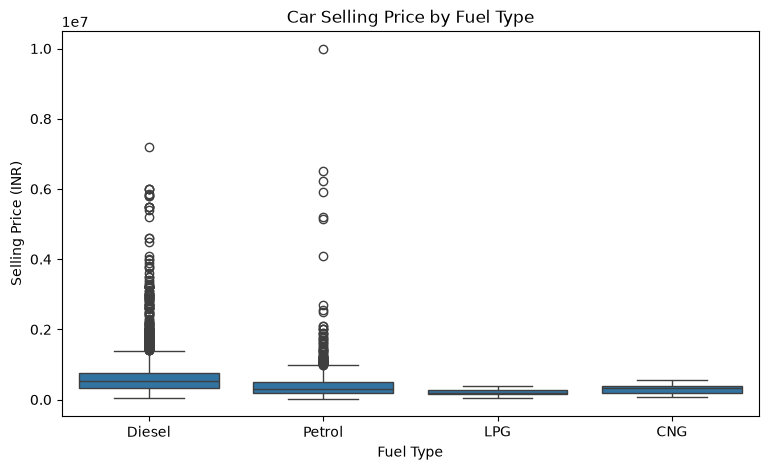

In [19]:
plt.figure(figsize=(9, 5))

sns.boxplot(x="fuel", y="selling_price", data=df)

plt.title("Car Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (INR)")

plt.show()

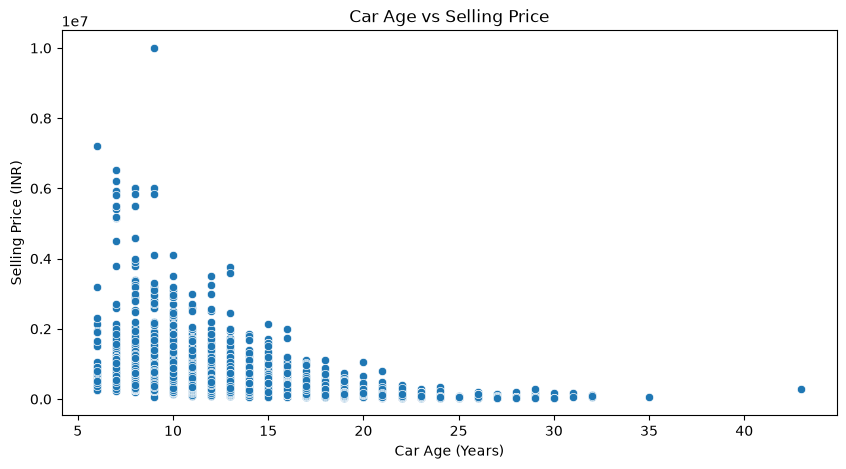

In [20]:
plt.figure(figsize=(10, 5))

sns.scatterplot(x="car_age", y="selling_price", data=df)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (INR)")

plt.show()

In [21]:
X = df[
    ["car_age", "km_driven", "fuel", "seller_type",
     "transmission", "owner", "mileage", "engine",
     "max_power", "seats", "brand"]
]

y = df["selling_price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6926, 11)
Target shape: (6926,)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5540, 11)
Testing data: (1386, 11)


In [23]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = [
    "fuel", "seller_type", "transmission", "owner", "brand"
]

numerical_features = [
    "car_age", "km_driven", "mileage", "engine",
    "max_power", "seats"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

print("Categorical and numerical features configured successfully!")

Categorical and numerical features configured successfully!


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [25]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [26]:
y_pred_linear = linear_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

print("Predictions completed successfully!")

print("Linear Regression predictions:", y_pred_linear[:5])
print("Random Forest predictions:", y_pred_rf[:5])

Predictions completed successfully!
Linear Regression predictions: [ 499101.7952654  1248569.61497028  783286.03138606   75555.53523989
  793770.18283695]
Random Forest predictions: [ 687999.98       1058921.45666667  834586.66666667  149729.96
  694310.        ]


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Linear Regression evaluation
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

# Random Forest evaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Linear Regression Results")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

print("\nRandom Forest Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Linear Regression Results
MAE: 167801.8683149162
RMSE: 298169.0890588971
R2 Score: 0.5946373073899158

Random Forest Results
MAE: 73392.46669581873
RMSE: 130599.1858168323
R2 Score: 0.9222322600273151


In [28]:
best_model = rf_model

print("Best Model: Random Forest Regression")
print("R2 Score:", r2_rf)

Best Model: Random Forest Regression
R2 Score: 0.9222322600273151


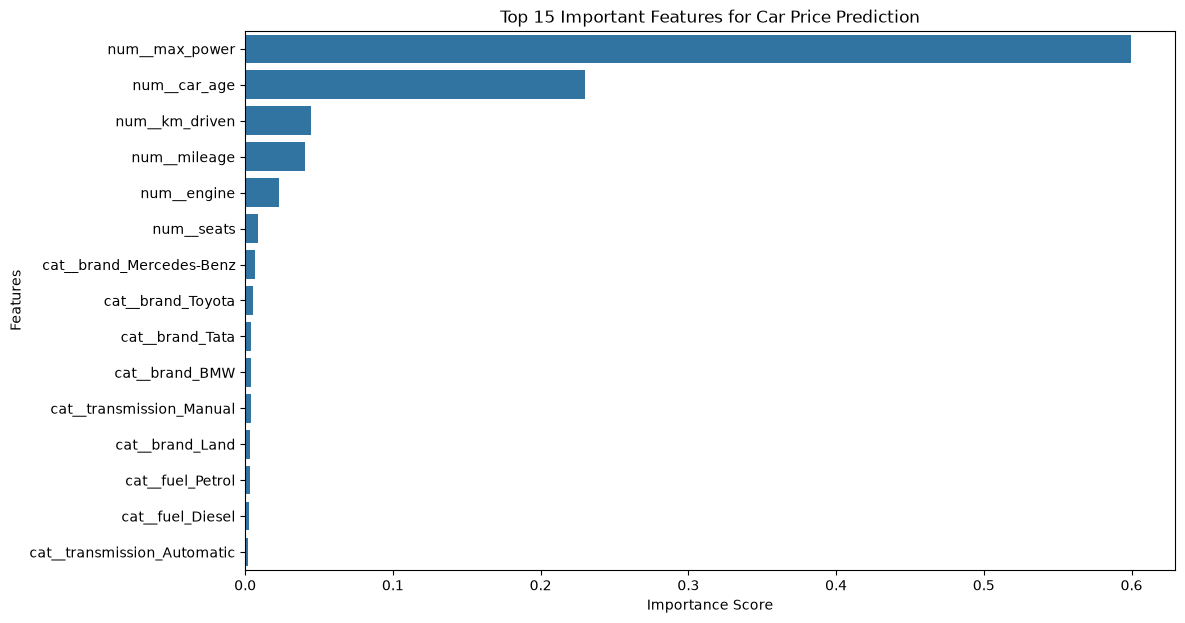

In [30]:
# Get feature importance from Random Forest
feature_importance = best_model.named_steps["model"].feature_importances_

# Get encoded feature names
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

# Plot feature importance
plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for Car Price Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [31]:
# Sample car details for prediction
sample_car = pd.DataFrame([{
    "car_age": 5,
    "km_driven": 50000,
    "fuel": "Petrol",
    "seller_type": "Individual",
    "transmission": "Manual",
    "owner": "First Owner",
    "mileage": 18.0,
    "engine": 1197.0,
    "max_power": 82.0,
    "seats": 5.0,
    "brand": "Maruti"
}])

# Predict the selling price
predicted_price = best_model.predict(sample_car)

# Display the predicted price
print("Predicted Car Selling Price: ₹", round(predicted_price[0], 2))

Predicted Car Selling Price: ₹ 550840.0


## Observations

1. The dataset contains 8,128 car records before duplicate removal.
2. Duplicate records and missing numerical values were handled during data cleaning.
3. Car age and brand were extracted as new features.
4. Random Forest Regression performed better than Linear Regression.

## Model Evaluation

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Linear Regression | 167801.87 | 298169.09 | 0.5946 |
| Random Forest | 73392.47 | 130599.19 | 0.9222 |

## Conclusion

Random Forest Regression was selected as the best model because it achieved an R² score of 0.9222 on the test dataset.

The model can predict used-car selling prices based on features such as car age, kilometers driven, fuel type, transmission, engine, and brand.

For a sample Maruti car, the predicted selling price was ₹5,50,840.

This project demonstrates how machine learning can be used to estimate used-car prices. Predictions are estimates and may differ from actual market prices.